# 04 — Đánh giá và giải thích mô hình

So sánh **Isolation Forest, One-Class SVM và Gradient Boosting** trên cùng tập test. Notebook tải các mô hình cùng cấu hình và ngưỡng đã lưu từ notebook 02–03.

Quy ước: `human = 0`, `bot = 1`; điểm càng lớn càng được mô hình xem là giống bot. Chạy notebook 02 và 03 trước để tạo các tệp trong `models/`.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if not (project_root / "src").is_dir():
    raise RuntimeError("Mở notebook từ thư mục gốc dự án hoặc notebooks/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FEATURE_COLUMNS, RANDOM_STATE
print("Project root:", project_root)


Project root: D:\Project\Social-Media-Bot-Fake-Account-Detection


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from src.config import FIGURES_DIR, REPORTS_DIR
from src.data import build_features, load_profiles, split_features
from src.evaluate import compare_models, feature_importance
from src.models import bot_scores, load_model

_, validation, test = split_features(build_features(load_profiles()))
y_test = test["label"].to_numpy()
bundles = {name: load_model(name) for name in ("isolation_forest", "one_class_svm", "gradient_boosting")}
display(pd.DataFrame({
    name: {"config": bundle["config"], "validation_f1_threshold": bundle["threshold"]}
    for name, bundle in bundles.items()
}).T)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

,config,validation_f1_threshold
isolation_forest,{'n_estimators': 300},-0.127698
one_class_svm,"{'nu': 0.05, 'gamma': 0.05}",-97.557444
gradient_boosting,"{'n_estimators': 200, 'max_depth': 4}",0.369156


## Các thiết lập đánh giá

Mỗi mô hình được đánh giá với quyết định mặc định và ngưỡng F1 đã chọn trên validation. Các chỉ số gồm precision, recall, F1 lớp bot, Macro-F1, AP, ROC-AUC và accuracy. Giữ nguyên mô hình và ngưỡng khi chuyển từ validation sang test.

In [3]:
validation_results = compare_models(bundles, validation, "validation")
validation_results.to_csv(REPORTS_DIR / "comparison_validation_metrics.csv", index=False)

# Chỉ đánh giá test sau khi cấu hình và ngưỡng đã cố định trên validation.
metrics = compare_models(bundles, test, "test")
metrics.to_csv(REPORTS_DIR / "metrics.csv", index=False)
print("Đã lưu các bảng so sánh vào reports/.")

bot_share = y_test.mean()
print(f"Mốc trên test: tỷ lệ bot {bot_share:.3f}; tất cả là bot cho F1 {2 * bot_share / (1 + bot_share):.3f}")
display(metrics.round(4))

Đã lưu các bảng so sánh vào reports/.
Mốc trên test: tỷ lệ bot 0.332; tất cả là bot cho F1 0.498


,split,model,setting,threshold,precision_bot,recall_bot,f1_bot,macro_f1,ap,roc_auc,accuracy,tn,fp,fn,tp
0,test,isolation_forest,default,NaN,0.2852,0.0897,0.1365,0.4478,0.2809,0.3685,0.6233,4444,559,2262,223
1,test,isolation_forest,validation_f1,-0.1277,0.3316,0.9984,0.4978,0.2493,0.2809,0.3685,0.3316,2,5001,4,2481
2,test,one_class_svm,default,NaN,0.3610,0.0543,0.0944,0.4404,0.3731,0.5643,0.6542,4764,239,2350,135
3,test,one_class_svm,validation_f1,-97.5574,0.3479,0.8636,0.4960,0.4032,0.3731,0.5643,0.4176,981,4022,339,2146
4,test,gradient_boosting,default,NaN,0.7561,0.6326,0.6889,0.7762,0.7889,0.8613,0.8104,4496,507,913,1572
5,test,gradient_boosting,validation_f1,0.3692,0.6795,0.7328,0.7051,0.7749,0.7889,0.8613,0.7966,4144,859,664,1821


## So sánh validation và test

Đối chiếu F1 lớp bot, Macro-F1, AP và ROC-AUC giữa hai tập để xem mức chênh lệch hiệu quả của từng mô hình.

In [4]:
keys = ["model", "setting"]
comparison = validation_results[keys + ["f1_bot", "macro_f1", "ap", "roc_auc"]].merge(
    metrics[keys + ["f1_bot", "macro_f1", "ap", "roc_auc"]], on=keys, suffixes=("_val", "_test"),
)
display(comparison.round(3))

,model,setting,f1_bot_val,macro_f1_val,ap_val,roc_auc_val,f1_bot_test,macro_f1_test,ap_test,roc_auc_test
0,isolation_forest,default,0.152,0.458,0.288,0.378,0.137,0.448,0.281,0.368
1,isolation_forest,validation_f1,0.498,0.249,0.288,0.378,0.498,0.249,0.281,0.368
2,one_class_svm,default,0.087,0.436,0.372,0.565,0.094,0.440,0.373,0.564
3,one_class_svm,validation_f1,0.501,0.407,0.372,0.565,0.496,0.403,0.373,0.564
4,gradient_boosting,default,0.695,0.782,0.788,0.862,0.689,0.776,0.789,0.861
5,gradient_boosting,validation_f1,0.709,0.778,0.788,0.862,0.705,0.775,0.789,0.861


## Biểu đồ

Biểu đồ so sánh ba mô hình; đường tham chiếu màu xám biểu thị tỷ lệ bot. Số liệu đầy đủ nằm trong `reports/metrics.csv`.

In [5]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
MODEL_COLORS = {"gradient_boosting": "#2a78d6", "isolation_forest": "#eb6834", "one_class_svm": "#1baf7a"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": MUTED, "axes.edgecolor": GRID, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11,
})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(fig, filename):
    fig.savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")
    print("Đã lưu:", (FIGURES_DIR / filename).relative_to(project_root).as_posix())

Đã lưu: reports/figures/precision_recall_test.png


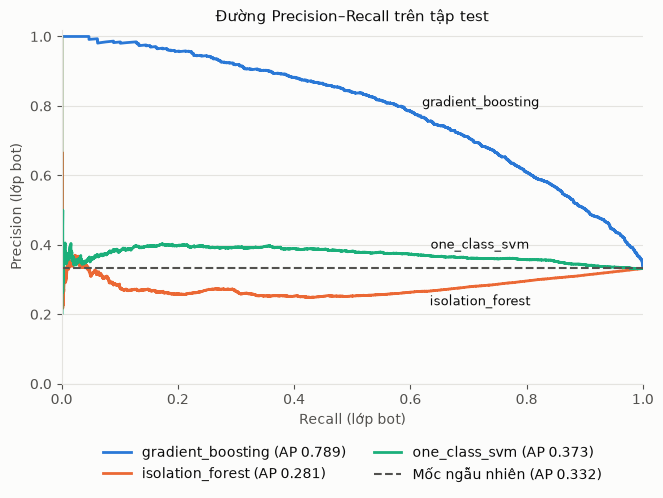

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ap_by_model = metrics.groupby("model")["ap"].first()
label_points = {"gradient_boosting": (0.62, 8), "one_class_svm": (0.72, 7), "isolation_forest": (0.72, -14)}
for name, color in MODEL_COLORS.items():
    precision, recall, _ = precision_recall_curve(y_test, bot_scores(bundles[name]["model"], test))
    legend_label = f"{name} (AP {ap_by_model[name]:.3f})"
    ax.plot(recall, precision, color=color, linewidth=2, label=legend_label)
    target_recall, offset = label_points[name]
    point = np.argmin(np.abs(recall - target_recall))
    ax.annotate(name, (recall[point], precision[point]), xytext=(0, offset), textcoords="offset points",
                color=INK, ha="left" if name == "gradient_boosting" else "center", fontsize=9)
ax.axhline(bot_share, color=MUTED, linestyle="--", linewidth=1.5, label=f"Mốc ngẫu nhiên (AP {bot_share:.3f})")
ax.set(title="Đường Precision–Recall trên tập test", xlabel="Recall (lớp bot)", ylabel="Precision (lớp bot)",
       xlim=(0, 1), ylim=(0, 1.02))
ax.grid(axis="y", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
save_figure(fig, "precision_recall_test.png")
plt.show()

Đã lưu: reports/figures/confusion_matrices_test.png


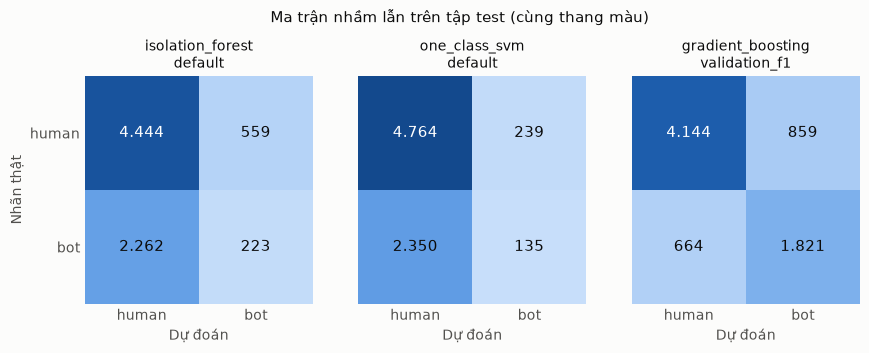

In [7]:
panels = [
    ("isolation_forest", "default"),
    ("one_class_svm", "default"), ("gradient_boosting", "validation_f1"),
]
BLUE_RAMP = ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"]
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", BLUE_RAMP)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, (name, setting) in zip(axes, panels):
    row = metrics[(metrics["model"] == name) & (metrics["setting"] == setting)].iloc[0]
    matrix = np.array([[row["tn"], row["fp"]], [row["fn"], row["tp"]]])
    ax.imshow(matrix, cmap=cmap, vmin=0, vmax=len(y_test) * (1 - bot_share))
    for (i, j), count in np.ndenumerate(matrix):
        dark_cell = count > 0.5 * len(y_test) * (1 - bot_share)
        ax.text(j, i, f"{count:,}".replace(",", "."), ha="center", va="center",
                color="white" if dark_cell else INK, fontsize=11)
    ax.set_title(f"{name}\n{setting}", fontsize=10)
    ax.set_xticks([0, 1], ["human", "bot"])
    ax.set_yticks([0, 1], ["human", "bot"])
    ax.set_xlabel("Dự đoán")
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel("Nhãn thật")
fig.suptitle("Ma trận nhầm lẫn trên tập test (cùng thang màu)", y=1.06, fontsize=11)
save_figure(fig, "confusion_matrices_test.png")
plt.show()

## Ảnh hưởng của đặc trưng trong Gradient Boosting

- `feature_importances_`: mức giảm impurity trên **train**; không phụ thuộc dữ liệu đánh giá nhưng có thể thiên về đặc trưng nhiều giá trị khác nhau.
- Permutation importance: mức giảm AP trên **validation** khi xáo trộn một đặc trưng (10 lần lặp). Test không được dùng cho phần này.

Importance cho biết mô hình dựa vào đặc trưng nào, không phải quan hệ nhân quả.

,feature,impurity_importance,permutation_ap_drop,permutation_ap_drop_std
0,posting_frequency,0.3908,0.2082,0.0054
1,account_age_days,0.2327,0.1533,0.0046
2,follower_following_ratio,0.2208,0.1527,0.0054
3,bio_length,0.1557,0.0773,0.0044


Đã lưu: reports/figures/feature_importance_gb.png


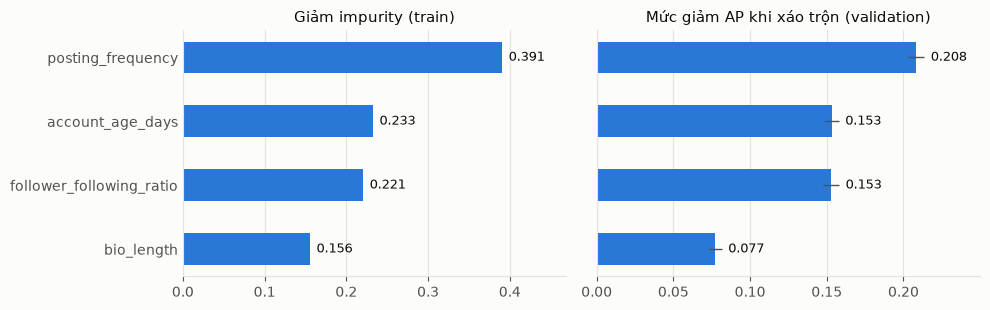

In [8]:
importance = feature_importance(bundles["gradient_boosting"]["model"], validation)
importance.to_csv(REPORTS_DIR / "feature_importance.csv", index=False)
display(importance.round(4))

order = importance.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
panels = (
    ("impurity_importance", None, "Giảm impurity (train)", "{:.3f}"),
    ("permutation_ap_drop", "permutation_ap_drop_std", "Mức giảm AP khi xáo trộn (validation)", "{:.3f}"),
)
for ax, (column, error, title, fmt) in zip(axes, panels):
    bars = ax.barh(order["feature"], order[column], height=0.5, color="#2a78d6",
                   xerr=order[error] if error else None, error_kw={"ecolor": MUTED, "linewidth": 1})
    offset = (order[error].to_numpy() if error else np.zeros(len(order)))
    for bar, extra, value in zip(bars, offset, order[column]):
        ax.text(value + extra + order[column].max() * 0.02, bar.get_y() + bar.get_height() / 2,
                fmt.format(value), va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlim(0, order[column].max() * 1.2)
    ax.grid(axis="x", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
fig.tight_layout()
save_figure(fig, "feature_importance_gb.png")
plt.show()

## Kết luận và giới hạn

Bảng tổng hợp dưới đây sử dụng ngưỡng F1 đã chọn trên validation. Đối chiếu AP, F1 lớp bot và Macro-F1 để so sánh ba mô hình; tham khảo thêm ma trận nhầm lẫn và mốc gắn nhãn tất cả là bot.

Các giới hạn cần lưu ý khi diễn giải kết quả:

- Chỉ dùng bốn đặc trưng hồ sơ, chưa có nội dung bài đăng hoặc mạng lưới tương tác.
- Tần suất đăng là trung bình cả vòng đời; tuổi tài khoản lấy từ dữ liệu nguồn, không phản ánh trực tiếp hoạt động gần đây.
- Kết quả thuộc một bộ dữ liệu và một lần chia ngẫu nhiên, chưa có khoảng tin cậy hoặc đánh giá theo thời gian.
- Feature importance thể hiện mức mô hình sử dụng đặc trưng, không chứng minh quan hệ nhân quả.
- Dự đoán có thể nhầm; kết quả phân loại bot không đủ để kết luận một tài khoản giả mạo hay lừa đảo.

In [9]:
from IPython.display import Markdown

selected = metrics[metrics["setting"].eq("validation_f1")]
display(selected[["model", "setting", "precision_bot", "recall_bot", "f1_bot", "macro_f1", "ap", "roc_auc", "accuracy"]].round(4))
gb = selected[selected["model"].eq("gradient_boosting")].iloc[0]
display(Markdown(
    f"Gradient Boosting trên test: **F1 bot {gb['f1_bot']:.4f}**, "
    f"**AP {gb['ap']:.4f}**, **ROC-AUC {gb['roc_auc']:.4f}**. "
    f"Đặc trưng có permutation importance lớn nhất: **{importance.iloc[0]['feature']}** "
    f"(AP giảm {importance.iloc[0]['permutation_ap_drop']:.4f} trên validation). "
    "Cấu hình và ngưỡng giữ nguyên từ notebook 03."
))

,model,setting,precision_bot,recall_bot,f1_bot,macro_f1,ap,roc_auc,accuracy
1,isolation_forest,validation_f1,0.3316,0.9984,0.4978,0.2493,0.2809,0.3685,0.3316
3,one_class_svm,validation_f1,0.3479,0.8636,0.4960,0.4032,0.3731,0.5643,0.4176
5,gradient_boosting,validation_f1,0.6795,0.7328,0.7051,0.7749,0.7889,0.8613,0.7966


Gradient Boosting trên test: **F1 bot 0.7051**, **AP 0.7889**, **ROC-AUC 0.8613**. Đặc trưng có permutation importance lớn nhất: **posting_frequency** (AP giảm 0.2082 trên validation). Cấu hình và ngưỡng giữ nguyên từ notebook 03.